In [1]:
import cv2 
import numpy as np
from matplotlib import pyplot as plt
from matplotlib import image as image

In [4]:
I = cv2.imread("poolTable.png")

# convert to greyscale
G = cv2.cvtColor(I, cv2.COLOR_BGR2GRAY)

# median blur filtering to reduce noise
G = cv2.medianBlur(G, 5)


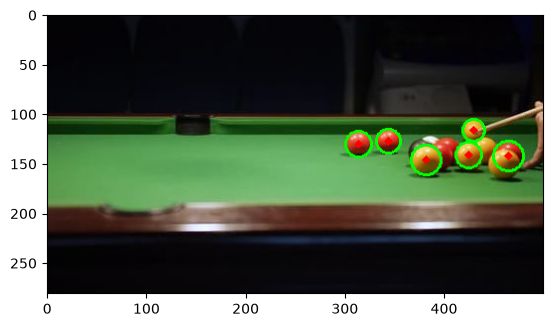

In [13]:
# Detect circles in the greyscale image using Hough Circle Transform
circles = cv2.HoughCircles(
    G,
    cv2.HOUGH_GRADIENT,
    dp=1.2,
    minDist=25,       # Minimum distance between detected circle centres
    param1=100,       # Higher threshold for the Canny edge detector
    param2=20,        # Threshold for detecting circles
    minRadius=10,     # Minimum expected ball radius
    maxRadius=18      # Maximum expected ball radius
)

#  copy of the original image to draw the detected circles on
C = I.copy()

# check if the circles were detected
if circles is not None:
    circles = np.uint16(np.around(circles))

    for x, y, r in circles[0]:
        cv2.circle(C, (x, y), r, (0, 255, 0), 2)
    
        # Draw the detected circle
        cv2.circle(C, (x, y), r, (0, 255, 0), 2)

        # Mark the centre of the circle
        cv2.circle(C, (x, y), 2, (0, 0, 255), 3)

plt.imshow(cv2.cvtColor(C, cv2.COLOR_BGR2RGB))
plt.show()